/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


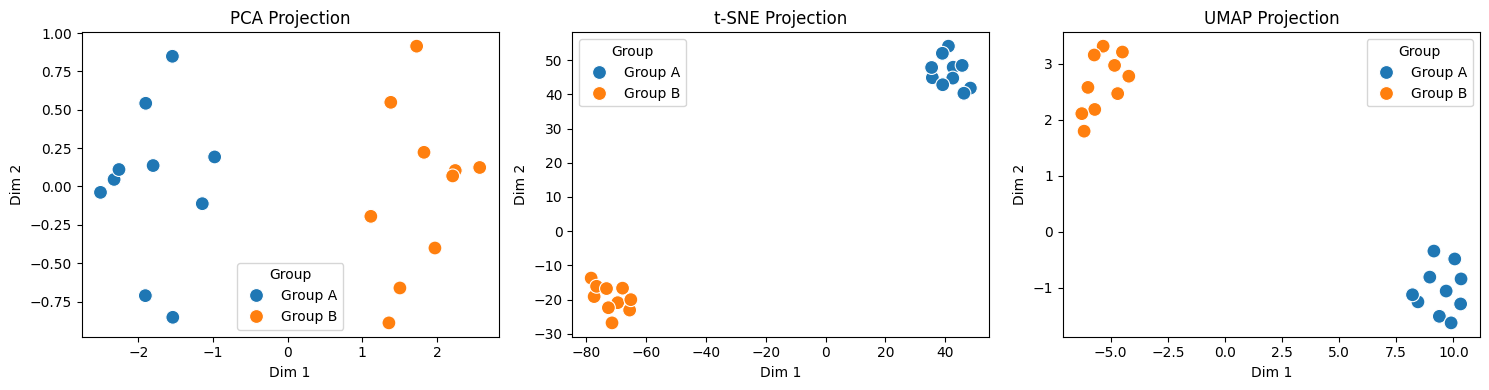

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# --- DATASET GENERATION (Do not change) ---
np.random.seed(42)

data = np.random.randn(20, 4)
data[10:, :] += 3.5  # Create 2 groups

labels = ['Group A'] * 10 + ['Group B'] * 10

df = pd.DataFrame(data, columns=['F1', 'F2', 'F3', 'F4'])

X_scaled = StandardScaler().fit_transform(df)

# PCA
pca_res = PCA(n_components=2).fit_transform(X_scaled)

# t-SNE
tsne_res = TSNE(
    n_components=2,
    perplexity=5,
    random_state=42
).fit_transform(X_scaled)

# UMAP
umap_res = umap.UMAP(
    n_components=2,
    n_neighbors=5,
    random_state=42
).fit_transform(X_scaled)

# Plot all three
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

results = [
    ('PCA', pca_res),
    ('t-SNE', tsne_res),
    ('UMAP', umap_res)
]

for ax, (title, res_data) in zip(axes, results):
    plot_df = pd.DataFrame(
        res_data,
        columns=['Dim 1', 'Dim 2']
    )

    plot_df['Group'] = labels

    sns.scatterplot(
        data=plot_df,
        x='Dim 1',
        y='Dim 2',
        hue='Group',
        ax=ax,
        s=100
    )

    ax.set_title(f"{title} Projection")

plt.tight_layout()
plt.show()